<a target="_blank" href="https://colab.research.google.com/github/heechul/eecs635/blob/main/l5-vww/train-person.ipynb">
        <img src="https://i.ibb.co/2P3SLwK/colab.png"  style="padding-bottom:5px;" />Run in Google Colab</a>

# Person-Detection using Transfer Learning
In this assignment we will use transfer learning to detect if there is a human in a given image. We will use a pre-trained model (MobileNet-V2), which was trained on ImageNet dataset and use a [Kaggle human detection dataset](https://www.kaggle.com/datasets/constantinwerner/human-detection-dataset).

**Acknowledgements**

This colab is heavily borrowed from the [Google's Transfer learning](https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/images/transfer_learning.ipynb) Colab and [EdX TinyML course's](https://github.com/tinyMLx) Mask Detection Colab.


In [1]:
import os
import subprocess
import sys
from pathlib import Path

RunningInCOLAB = 'google.colab' in str(get_ipython())

if not RunningInCOLAB:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-r", "requirements-local.txt"
    ])

os.environ["TF_USE_LEGACY_KERAS"] = "1"
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

In [2]:
import matplotlib.pyplot as plt
import os
import tensorflow as tf

from tensorflow.keras.preprocessing import image_dataset_from_directory

# tf.debugging.set_log_device_placement(True)

# Suppress only PNG warnings
tf.get_logger().setLevel('ERROR')

RunningInCOLAB = 'google.colab' in str(get_ipython())

## Build the dataset

### Download the dataset

In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("constantinwerner/human-detection-dataset")
print("Path to dataset files:", path)

/Users/h488y928/Projects/EmbeddedML/l5-vww/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 260M/260M [00:06<00:00, 39.7MB/s] 

Extracting files...


Path to dataset files: /Users/h488y928/.cache/kagglehub/datasets/constantinwerner/human-detection-dataset/versions/5


In [4]:
# Use Kaggle's downloaded directory directly; leave its cache intact on reruns.
path = Path(path)
dataset_path = path / "human detection dataset"
print("Path to dataset files:", dataset_path)
print("Dataset contents:", sorted(entry.name for entry in dataset_path.iterdir()))

Path to dataset files: /Users/h488y928/.cache/kagglehub/datasets/constantinwerner/human-detection-dataset/versions/5/human detection dataset
Dataset contents: ['0', '1']


In [5]:
# Keep generated files in the notebook's working directory on every platform.
topdir = Path.cwd()
model_dir = topdir / "model"
src_dir = topdir / "src"
for directory in (model_dir, src_dir):
    directory.mkdir(parents=True, exist_ok=True)
print(topdir)

/Users/h488y928/Projects/EmbeddedML/l5-vww


In [6]:
import os
from tensorflow.keras.utils import image_dataset_from_directory

BATCH_SIZE = 32
IMG_SIZE = (96, 96)
dataset = image_dataset_from_directory(str(dataset_path),
                                        labels='inferred',
                                        label_mode='binary',
                                        shuffle=True,
                                        batch_size=BATCH_SIZE,
                                        image_size=IMG_SIZE)

dataset_size = len(list(dataset))  # Get the total number of elements in the dataset
train_size = int(0.8 * dataset_size) # Calculate the size of the training set (80%)
val_size = int(0.2 * dataset_size) # Calculate the size of the validation set (20%)

# Split the dataset into training and validation sets
train_dataset = dataset.take(train_size)
val_dataset = dataset.skip(train_size).take(val_size)

Found 921 files belonging to 2 classes.


Now that we have built the dataset lets view the first nine images and labels from the training set:

['0', '1']


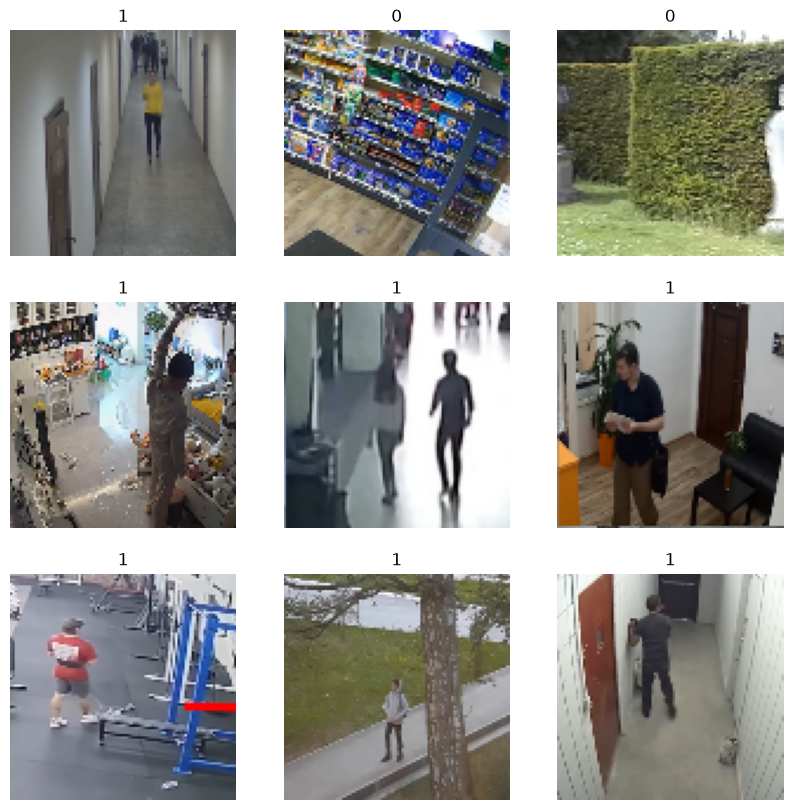

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

class_names = dataset.class_names
print (class_names)
plt.figure(figsize=(10, 10))
for images, labels in dataset.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    idx = labels[i].numpy().astype("uint8")[0]
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[idx])
    plt.axis("off")

### Rescale pixel values

In a moment, you will download `tf.keras.applications.MobileNetV2` for use as your base model. This model expects pixel vaues in `[-1,1]`, but at this point, the pixel values in your images are in `[0-255]`. To rescale them, use the preprocessing method included with the model.

In [8]:
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input

Note: Alternatively, you could rescale pixel values from `[0,255]` to `[-1, 1]` using a [Rescaling](https://www.tensorflow.org/api_docs/python/tf/keras/layers/experimental/preprocessing/Rescaling) layer.

Note: If you go on to use other `tf.keras.applications`, be sure to check the API doc to determine if they expect pixels in `[-1,1]` or `[0,1]`, or use the included `preprocess_input` function.

## Build the Model

### Create the base model
You will create the base model from the **MobileNet V2** model developed at Google. This is pre-trained on the ImageNet dataset, a large dataset consisting of 1.4M images and 1000 classes. ImageNet is a research training dataset with a wide variety of categories including objects such as `jackfruit` and `syringe`. This base of knowledge will help us classify if a person exists or not from our specific dataset.

First, you need to pick which layer of MobileNet V2 you will leverage as the high level features you wish to re-use. Since we want to adapt the classifications coming out of the model to a new task, we want to leverage the features coming out of the *last* layer BEFORE the classification layers. In many image models this is the output of the final convolution BEFORE the flatten layer. You may see this layer referred to as the "bottleneck layer" in some texts. Since many machine learning models are defined as the inputs occuring at the bottom and the outputs occuring at the top we would like to ignore the top few classification layers. Fortuntately, there is a shortcut to doing this in TensorFlow, **```include_top=False```**. By passing in this parameter we instantiate a MobileNet V2 model pre-loaded with weights trained on ImageNet that doesn't include the classification layers at the top, which is ideal for feature extraction.

In [9]:
# Create the base model from the pre-trained model MobileNet V2
IMG_SHAPE = IMG_SIZE + (3,)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE,
                                               include_top=False,
                                               alpha=0.35,
                                               weights='imagenet')

In [10]:
image_batch, label_batch = next(iter(train_dataset))
feature_batch = base_model(image_batch)
print(feature_batch.shape)

(32, 3, 3, 1280)


### Freeze the convolutional layers

It is important to freeze the convolutional layers before you compile and train the model with transfer learning. Freezing (by setting layer.trainable = False) prevents the weights in a given layer from being updated during training. We want to perform this operation because we want to leverage the pre-trained values in the convolutional layers and only learn new classification layer values. We can do this by setting the entire model's `trainable` flag to False.

In [11]:
print (base_model.trainable)
base_model.trainable = False
print (base_model.trainable)


True
False


In [12]:
# Let's take a look at the base model architecture
base_model.summary()

Model: "mobilenetv2_0.35_96"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 96, 96, 3)]          0         []                            
                                                                                                  
 Conv1 (Conv2D)              (None, 48, 48, 16)           432       ['input_1[0][0]']             
                                                                                                  
 bn_Conv1 (BatchNormalizati  (None, 48, 48, 16)           64        ['Conv1[0][0]']               
 on)                                                                                              
                                                                                                  
 Conv1_relu (ReLU)           (None, 48, 48, 16)           0         ['bn_Conv1[0

### Add a classification head

To begin the process of generating classifications from the pretrained features, we use a `tf.keras.layers.GlobalAveragePooling2D` layer to convert the 3x3 spatial features into a single 1024-element feature vector per image.

In [13]:
classification_input_layer = tf.keras.layers.Flatten()
# classification_input_layer = tf.keras.layers.GlobalAveragePooling2D()

feature_batch_average = classification_input_layer(feature_batch)
print(feature_batch_average.shape)

(32, 11520)


We then apply a `tf.keras.layers.Dense` layer to convert the feature vector into a single prediction per image. You don't need an activation function here because this prediction will be treated as a `logit`, or a raw prediction value.  Positive numbers predict class 1, negative numbers predict class 0.

In [14]:
prediction_layer = tf.keras.layers.Dense(1, activation='sigmoid')
prediction_batch = prediction_layer(feature_batch_average)
print(prediction_batch.shape)

(32, 1)


We can then build our final model by chaining together the data augmentation, rescaling, base_model and feature extractor layers using the [Keras Functional API](https://www.tensorflow.org/guide/keras/functional). Importantly we remind Tensorflow that we do not want to train the base_model!

In [15]:
inputs = tf.keras.Input(shape=(96, 96, 3))
x = preprocess_input(inputs)
x = base_model(x, training=False)
x = classification_input_layer(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)

### Compile the model

Compile the model before training it. Since there are two classes, use a binary cross-entropy loss with `from_logits=True` since the model provides a linear output. You can see below how we have included the Mobilenet V1 model after the input layer and before our classification layers!

In [16]:
base_learning_rate = 0.0001
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=base_learning_rate),
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=['accuracy'])

In [17]:
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 96, 96, 3)]       0         
                                                                 
 tf.math.truediv (TFOpLambd  (None, 96, 96, 3)         0         
 a)                                                              
                                                                 
 tf.math.subtract (TFOpLamb  (None, 96, 96, 3)         0         
 da)                                                             
                                                                 
 mobilenetv2_0.35_96 (Funct  (None, 3, 3, 1280)        410208    
 ional)                                                          
                                                                 
 flatten (Flatten)           (None, 11520)             0         
                                                             

## Your Turn: Train and Evaluate the model

Now that we have our model we can train it! You will see that since we are leveraging all of the pre-trained features we can improve our model from a random initialization (accuracy of ~50%) to a model with over 95% accuracy quite quickly. **How many epochs do you think we'll need?**

### Train the model
First print the initial accuracy

In [18]:
loss, accuracy = model.evaluate(val_dataset)
print('Test accuracy :', accuracy)

5/5 [==============================] - 3s 31ms/step - loss: 0.9997 - accuracy: 0.4437
Test accuracy : 0.4437499940395355


**Now its your turn to pick the number of epochs of training! Remmeber we are aiming for at least 95% accuracy on the test set!**

*Hint: Despite the fact that it would take more than a day to train this model from scratch, it requires far fewer epochs to train it with transfer learning than you might suspect! You probably have more fingers and toes than the number of epochs you will need!*

In [19]:
EPOCHS = 20  
history = model.fit(train_dataset,
                    epochs=EPOCHS,
                    validation_data=val_dataset,
                    callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])


Epoch 1/20
23/23 [==============================] - 6s 197ms/step - loss: 0.8507 - accuracy: 0.5543 - val_loss: 0.7297 - val_accuracy: 0.6250
Epoch 2/20
23/23 [==============================] - 5s 193ms/step - loss: 0.6276 - accuracy: 0.7011 - val_loss: 0.4779 - val_accuracy: 0.7437
Epoch 3/20
23/23 [==============================] - 5s 199ms/step - loss: 0.4971 - accuracy: 0.7731 - val_loss: 0.4421 - val_accuracy: 0.7937
Epoch 4/20
23/23 [==============================] - 5s 208ms/step - loss: 0.4079 - accuracy: 0.8125 - val_loss: 0.4337 - val_accuracy: 0.8188
Epoch 5/20
23/23 [==============================] - 5s 184ms/step - loss: 0.3553 - accuracy: 0.8451 - val_loss: 0.3330 - val_accuracy: 0.8687
Epoch 6/20
23/23 [==============================] - 5s 178ms/step - loss: 0.3287 - accuracy: 0.8587 - val_loss: 0.3559 - val_accuracy: 0.8500
Epoch 7/20
23/23 [==============================] - 5s 175ms/step - loss: 0.3069 - accuracy: 0.8682 - val_loss: 0.3362 - val_accuracy: 0.8500
Epoch 

Did you hit you accuracy goal? Did you overshoot and spend some extra time training? When might you have been able to quit? Lets take a look at the learning curves of the training and validation accuracy/loss to analyze our results.

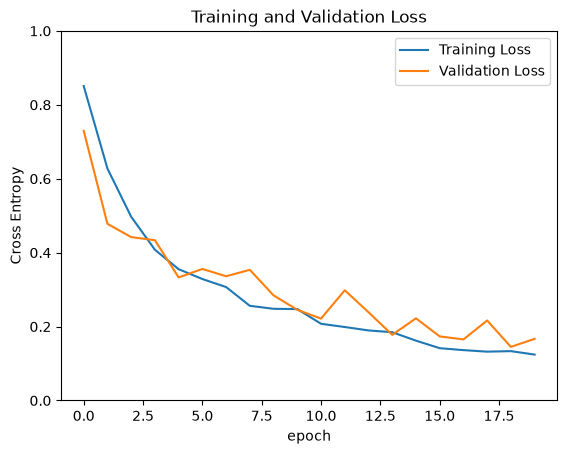

In [20]:
loss = history.history['loss']
val_loss = history.history['val_loss']
# plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.ylim([0,1.0])
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

### Evaluate your model

The last thing we need to do is check if the model is overfitting or if it actually learned the problem that fast! Does you model still perform well on the test set? Lets find out!

In [21]:
loss, accuracy = model.evaluate(val_dataset)
print('Test accuracy :', accuracy)

5/5 [==============================] - 2s 16ms/step - loss: 0.1742 - accuracy: 0.9375
Test accuracy : 0.9375


And assuming your model passed the accuracy threshold you are now are all set to use this model to predict if the person exists or not. Lets print the results from a bunch of the images in our test dataset!


Predictions:
 [0 1 1 1 1 1 0 0 0 1 0 1 1 1 0 0 0 0 1 1 1 1 1 1 0 1 1 0 0 1 0 1]
Labels:
 [0 1 1 1 1 1 0 0 1 1 0 1 1 1 0 0 0 0 1 1 1 1 1 1 0 1 1 0 0 1 0 1]


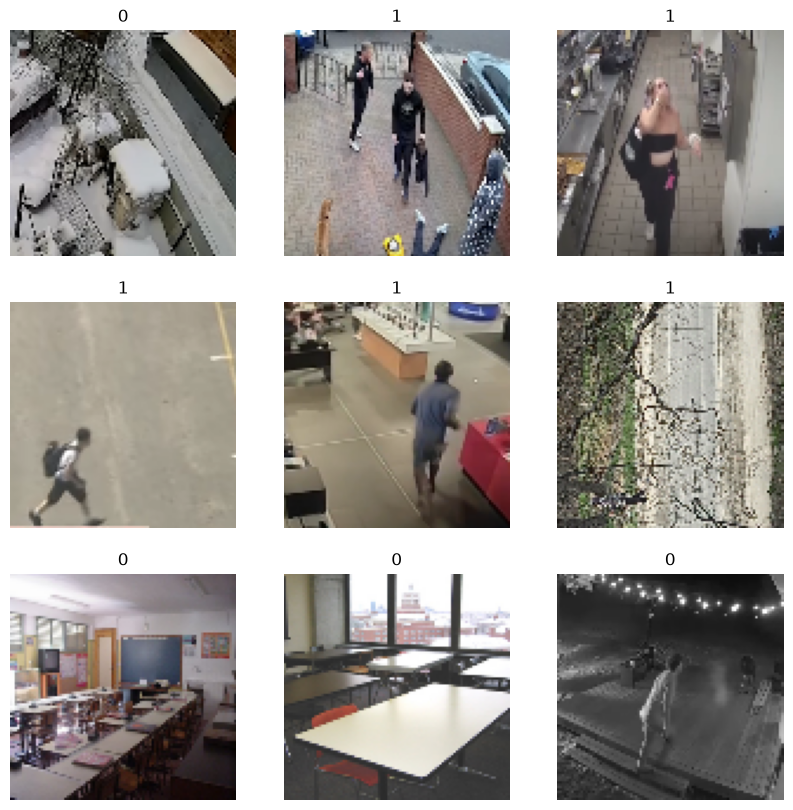

In [22]:
#Retrieve a batch of images from the test set
image_batch, label_batch = val_dataset.as_numpy_iterator().next()
predictions = model.predict_on_batch(image_batch).flatten()

predictions = tf.where(predictions < 0.5, 0, 1)

print('Predictions:\n', predictions.numpy())
print('Labels:\n', label_batch.reshape(-1).astype("uint8"))

plt.figure(figsize=(10, 10))
for i in range(9):
  ax = plt.subplot(3, 3, i + 1)
  plt.imshow(image_batch[i].astype("uint8"))
  plt.title(class_names[predictions[i]])
  plt.axis("off")

## Summary

* **Using transfer learning for Person Detection**: In this lab, we learned how we can use transfer learning to detect if a person exists or not. When working with a small dataset, it is a common practice to take advantage of features learned by a model trained on a larger dataset in the same domain.



# Model conversion

## Original float model

In [23]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT] # dynamic range quantization. size reduction but computing is done in fp32
tflite_model = converter.convert()

tflite_model_file = model_dir / "model-float32.tflite"
tflite_model_file.write_bytes(tflite_model)

W0000 00:00:1794503739.013547 1483638 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1794503739.014392 1483638 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
I0000 00:00:1794503739.089379 1483638 mlir_graph_optimization_pass.cc:425] MLIR V1 optimization pass is not enabled


550352

## Quantized model

In [24]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]  

def representative_data_get():
    for input_value, _ in val_dataset.take(100):
        yield [input_value]

converter.representative_dataset = representative_data_get
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
tflite_model_quant = converter.convert()
tflite_model_quant_file = model_dir / "model-int8.tflite"
tflite_model_quant_file.write_bytes(tflite_model_quant)

/Users/h488y928/Projects/EmbeddedML/l5-vww/.venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:854: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1794503748.404105 1483638 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1794503748.404132 1483638 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.
fully_quantize: 0, inference_type: 6, input_inference_type: FLOAT32, output_inference_type: FLOAT32


625144

## Inference

In [25]:
image_batch, label_batch = val_dataset.as_numpy_iterator().next()
img = image_batch[0,:,:,:]
print (img.flatten())

# Write a C source file of the image for debugging purposes (to check if the model output is correct)
with (src_dir / "img.h").open("w", encoding="utf-8") as f:
    f.write('#ifndef IMG_TEST_DATA\n')
    f.write('#define IMG_TEST_DATA\n')
    f.write('const float img_data[] = {')
    for i in range(0, len(img.flatten())):
        f.write(str(img.flatten()[i]))
        if i < len(img.flatten()) - 1:
            f.write(',')    
    f.write('};\n')
    f.write('#endif\n')

[153.33334  159.16667  133.66667  ...  42.749996  45.888885  11.888887]


In [26]:
interpreter = tf.lite.Interpreter(model_path=str(tflite_model_quant_file))
interpreter.allocate_tensors()
input_index = interpreter.get_input_details()[0]["index"]
output_index = interpreter.get_output_details()[0]["index"]
interpreter.set_tensor(input_index, np.expand_dims(img, axis=0))
interpreter.invoke()
output = interpreter.get_tensor(output_index)
print(output.flatten())
if output.flatten()[0] >= 0.5:
    print("Person")
else:
    print("No person")

[0.77734375]
Person


/Users/h488y928/Projects/EmbeddedML/l5-vww/.venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


(96, 96, 3)
[153 159 133]
[153.33334 159.16667 133.66667]


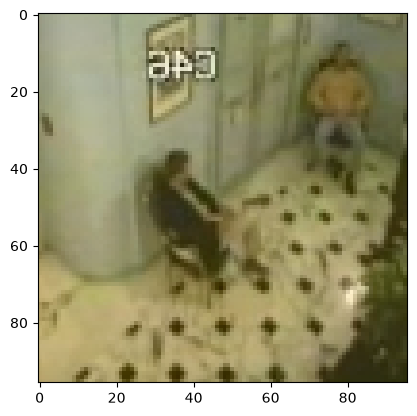

In [27]:
plt.imshow(img.astype("uint8"))
print(img.astype("uint8").shape)
print(img.astype("uint8").flatten()[:3])
print(img.astype("float32").flatten()[:3])

In [28]:
from tqdm import tqdm

def evaluate_model(interpreter):
    input_index = interpreter.get_input_details()[0]["index"]
    output_index = interpreter.get_output_details()[0]["index"]

    prediction_digits = []
    test_labels = []

    for test_image, test_label in tqdm(val_dataset):
        for i in range(len(test_label)):
            interpreter.set_tensor(input_index, np.expand_dims(test_image[i], axis=0))
            interpreter.invoke()
            prediction_digits.append(interpreter.get_tensor(output_index))
            test_labels.append(test_label[i])
    prediction_digits = np.array(prediction_digits).flatten().reshape(-1, 1)
    print(prediction_digits[:10])
    test_labels = np.array(test_labels)
    print(test_labels[:10])
    prediction_digits = np.where(prediction_digits < 0.5, 0, 1)
    print(prediction_digits[:10])

    accuracy = (prediction_digits == test_labels).mean()
    return accuracy

interpreter = tf.lite.Interpreter(model_path=str(tflite_model_file))
interpreter.allocate_tensors()
test_accuracy = evaluate_model(interpreter)

print('Float model accuracy = ', test_accuracy)

interpreter = tf.lite.Interpreter(model_path=str(tflite_model_quant_file))
interpreter.allocate_tensors()
test_accuracy = evaluate_model(interpreter)

print('Quantized model accuracy = ', test_accuracy)


100%|██████████| 5/5 [00:02<00:00,  2.07it/s]


[[0.969937  ]
 [0.98285306]
 [0.54558265]
 [0.02757241]
 [0.8617299 ]
 [0.4955827 ]
 [0.01093251]
 [0.03055559]
 [0.95798165]
 [0.96147805]]
[[1.]
 [1.]
 [1.]
 [0.]
 [1.]
 [1.]
 [0.]
 [0.]
 [1.]
 [1.]]
[[1]
 [1]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]]
Float model accuracy =  0.95


100%|██████████| 5/5 [00:02<00:00,  2.01it/s]

[[0.        ]
 [0.9765625 ]
 [0.99609375]
 [0.01171875]
 [0.953125  ]
 [0.19921875]
 [0.28125   ]
 [0.43359375]
 [0.98046875]
 [0.5       ]]
[[0.]
 [1.]
 [1.]
 [0.]
 [1.]
 [0.]
 [0.]
 [0.]
 [1.]
 [1.]]
[[0]
 [1]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]]
Quantized model accuracy =  0.9125


## Generate model CC file

Export the quantized model using Python. No system packages or shell utilities are required.

In [29]:
model_file = model_dir / "model-int8.tflite"
model_bytes = model_file.read_bytes()
model_cc_file = src_dir / "model.cc"

with model_cc_file.open("w", encoding="utf-8") as f:
    f.write("const unsigned char gmodel[] = {\n")
    for offset in range(0, len(model_bytes), 12):
        chunk = model_bytes[offset:offset + 12]
        f.write("  " + ", ".join(f"0x{byte:02x}" for byte in chunk) + ",\n")
    f.write("};\n")
    f.write(f"const unsigned int gmodel_len = {len(model_bytes)};\n")

print("C++ model written to:", model_cc_file)

C++ model written to: /Users/h488y928/Projects/EmbeddedML/l5-vww/src/model.cc
